# Analyse du data drift — API de scoring crédit

**Objectif.** Vérifier si les données reçues en production par l'API (`POST /predict`) restent
comparables aux données d'entraînement du modèle, et si le comportement du modèle (scores,
taux de refus) et de l'API (latence) reste stable.

**Données.**
- *Référence* : `data/processed/reference_sample.csv` — 20 000 demandes de `application_train.csv`
  (Home Credit) au format de l'API, écrites par `scripts/export_mlflow_model.py`.
- *Production* : `logs/predictions.jsonl` — une ligne JSON par appel à l'API (input complet, score,
  décision, latence), écrite par `src/scoring_api/logging_utils.py`. Le trafic a été généré par
  `scripts/simulate_traffic.py`, qui rejoue des clients réels de `application_test.csv` :
  - **session 1** : 300 demandes sans modification (trafic « normal ») ;
  - **session 2** : 150 demandes avec `--drift` — revenus ×1,6 et scores externes `ext_source_*` −0,15,
    pour simuler l'arrivée d'une nouvelle population.

**Méthode** (`src/scoring_api/monitoring/drift.py`, la même que le dashboard Streamlit et
`scripts/run_drift_analysis.py`) :

| Variable | Mesure | Lecture |
|---|---|---|
| numérique | **PSI** (Population Stability Index, 10 quantiles de la référence) + test de **Kolmogorov-Smirnov** | PSI < 0,10 stable · 0,10–0,25 modéré · > 0,25 significatif |
| catégorielle | **distance de variation totale** (½ Σ \|p_ref − p_prod\|) | mêmes seuils |

Le PSI est le standard du scoring crédit : il mesure l'ampleur du décalage, alors que la p-value du KS
devient significative pour des écarts minimes dès que les échantillons sont grands. On s'appuie donc
sur le PSI pour décider, et on utilise le KS comme confirmation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import json

import joblib
import pandas as pd

from scoring_api.features import RAW_COLUMNS, prepare_features
from scoring_api.monitoring.drift import build_drift_report, load_production_logs, psi, psi_level

pd.set_option("display.precision", 4)

In [2]:
# Fonctions de visualisation (palette commune à tout le notebook)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scoring_api.monitoring.drift import PSI_MODERATE_THRESHOLD, PSI_SIGNIFICANT_THRESHOLD

# Palette (theme "clean") — même couleur pour une même série dans tout le notebook
PALETTE = ["#3B6FD8", "#F2A33A", "#2BA88A", "#D9576B", "#7B61C9"]
NEUTRAL, TEXT, MUTED, GRID = "#A0A7B4", "#2B2F36", "#6B7280", "#E8EBF0"
COLORS = {"Référence (entraînement)": NEUTRAL, "Session 1 (normale)": PALETTE[0],
          "Session 2 (dérive simulée)": PALETTE[1]}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "font.size": 11, "legend.frameon": False,
})


def set_title(ax, title: str, subtitle: str | None = None) -> None:
    ax.set_title(title, loc="left", fontsize=14, color=TEXT, pad=28 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=MUTED)


def plot_psi_by_session(drift: pd.DataFrame) -> plt.Figure:
    """drift : colonnes feature, session, psi (une ligne par feature × session)."""
    pivot = drift.pivot(index="feature", columns="session", values="psi").fillna(0)
    pivot = pivot.loc[pivot.max(axis=1).sort_values().index]
    sessions = list(pivot.columns)
    y = np.arange(len(pivot))
    height = 0.8 / len(sessions)
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(pivot) + 1.8))
    for i, session in enumerate(sessions):
        ax.barh(y + i * height, pivot[session], height=height, label=session,
                color=COLORS[session])
    ax.set_yticks(y + height * (len(sessions) - 1) / 2, pivot.index)
    ax.axvline(PSI_MODERATE_THRESHOLD, color=PALETTE[1], ls="--", lw=1, label="Seuil modéré (0,10)")
    ax.axvline(PSI_SIGNIFICANT_THRESHOLD, color=PALETTE[3], ls="--", lw=1,
               label="Seuil significatif (0,25)")
    ax.set_xlabel("PSI (numériques) / distance de variation totale (catégorielles)")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    set_title(ax, "Dérive par variable et par session", "Comparaison à l'échantillon d'entraînement")
    fig.tight_layout()
    return fig


def plot_distributions(groups: dict[str, pd.DataFrame], features: list[str]) -> plt.Figure:
    """groups : {nom de série: DataFrame contenant les colonnes `features`}."""
    fig, axes = plt.subplots(1, len(features), figsize=(5 * len(features), 4.2))
    for ax, feature in zip(np.atleast_1d(axes), features):
        ref = pd.to_numeric(next(iter(groups.values()))[feature], errors="coerce").dropna()
        bins = np.linspace(ref.quantile(0.005), ref.quantile(0.995) * 1.8
                           if feature == "income_total" else ref.quantile(0.995), 40)
        for name, df in groups.items():
            values = pd.to_numeric(df[feature], errors="coerce").dropna()
            ax.hist(values, bins=bins, density=True, histtype="step", lw=2,
                    color=COLORS[name], label=name)
        ax.set_xlabel(feature)
        ax.set_ylabel("Densité")
        ax.set_yticks([])  # densités relatives : seule la forme compte
        ax.ticklabel_format(axis="x", style="plain")
        set_title(ax, feature)
    axes = np.atleast_1d(axes)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper left", ncol=len(groups), bbox_to_anchor=(0.01, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    return fig


def plot_scores(scores: dict[str, pd.Series], threshold: float) -> plt.Figure:
    """scores : {nom de série: Series de probabilités de défaut}."""
    fig, ax = plt.subplots(figsize=(9, 4.2))
    bins = np.linspace(0, 0.6, 40)
    for name, s in scores.items():
        ax.hist(s.clip(upper=0.6), bins=bins, density=True, histtype="step", lw=2,
                color=COLORS[name], label=name)
    ax.axvline(threshold, color=PALETTE[3], ls="--", lw=1, label=f"Seuil de décision ({threshold:.3f})")
    ax.set_xlabel("Probabilité de défaut prédite")
    ax.set_ylabel("Densité")
    ax.legend(loc="upper right")
    set_title(ax, "Distribution des scores prédits", "Scores > 0,6 regroupés dans la dernière classe")
    fig.tight_layout()
    return fig


def plot_latency(prod: pd.DataFrame) -> plt.Figure:
    """prod : colonnes logged_at (datetime), latency_ms, session."""
    prod = prod.sort_values("logged_at").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for session, df in prod.groupby("session"):
        ax.plot(df.index + 1, df["latency_ms"], marker="o", ms=2.5, lw=0.8,
                color=COLORS[session], label=session)
    p95 = prod["latency_ms"].quantile(0.95)
    ax.axhline(p95, color=NEUTRAL, ls="--", lw=1, label=f"p95 global ({p95:.1f} ms)")
    ax.set_yscale("log")
    ax.set_yticks([2, 5, 10, 20, 50, 100, 200])
    ax.set_ylim(prod["latency_ms"].min() * 0.8, prod["latency_ms"].max() * 1.2)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("N° de requête (ordre d'arrivée)")
    ax.set_ylabel("Latence (ms, échelle log)")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
    set_title(ax, "Latence de l'API par requête", " ")
    fig.tight_layout()
    return fig


## 1. Chargement des données

In [3]:
reference = pd.read_csv(ROOT / "data/processed/reference_sample.csv")[RAW_COLUMNS]
prod = load_production_logs(ROOT / "logs/predictions.jsonl")
prod["logged_at"] = pd.to_datetime(prod["logged_at"])

# Les deux sessions de trafic sont séparées par une pause : on les repère
# par un écart de plus de 5 s entre deux requêtes consécutives.
SESSION_NAMES = ["Session 1 (normale)", "Session 2 (dérive simulée)"]
session_id = (prod["logged_at"].diff() > pd.Timedelta(seconds=5)).cumsum()
prod["session"] = session_id.map(dict(enumerate(SESSION_NAMES)))

metadata = json.loads((ROOT / "models/metadata.json").read_text())
print(f"Référence  : {len(reference):,} lignes")
print(f"Production : {len(prod):,} requêtes — modèle {prod['model_version'].unique().tolist()}")
prod.groupby("session").agg(
    requetes=("score", "size"),
    debut=("logged_at", "min"),
    fin=("logged_at", "max"),
)

Référence  : 20,000 lignes
Production : 450 requêtes — modèle ['LightGBM-b8464ecf']


,requetes,debut,fin
session,,,
Session 1 (normale),300,2026-09-28 20:15:22.448141+00:00,2026-09-28 20:15:27.375194+00:00
Session 2 (dérive simulée),150,2026-09-28 20:15:43.180409+00:00,2026-09-28 20:15:45.633332+00:00


## 2. Dérive des variables d'entrée

On calcule le rapport de dérive séparément pour chaque session, afin de distinguer
la variabilité normale d'un vrai changement de population.

In [4]:
drift = pd.concat(
    [build_drift_report(reference, df).assign(session=name) for name, df in prod.groupby("session")],
    ignore_index=True,
)
drift.pivot(index="feature", columns="session", values="psi").sort_values(SESSION_NAMES[1], ascending=False)

session,Session 1 (normale),Session 2 (dérive simulée)
feature,,
ext_source_2,0.0240,2.0024
ext_source_3,0.0501,1.8064
income_total,0.0323,1.3480
ext_source_1,0.0509,1.0608
occupation_type,0.1519,0.1908
organization_type,0.1437,0.1634
credit_amount,0.1283,0.0910
years_employed,0.0482,0.0902
contract_type,0.0919,0.0819


In [5]:
summary = (
    drift.groupby(["session", "level"]).size().unstack(fill_value=0)
    .reindex(columns=["stable", "drift modere", "drift significatif"], fill_value=0)
)
summary

level,stable,drift modere,drift significatif
session,,,
Session 1 (normale),14,4,0
Session 2 (dérive simulée),12,2,4


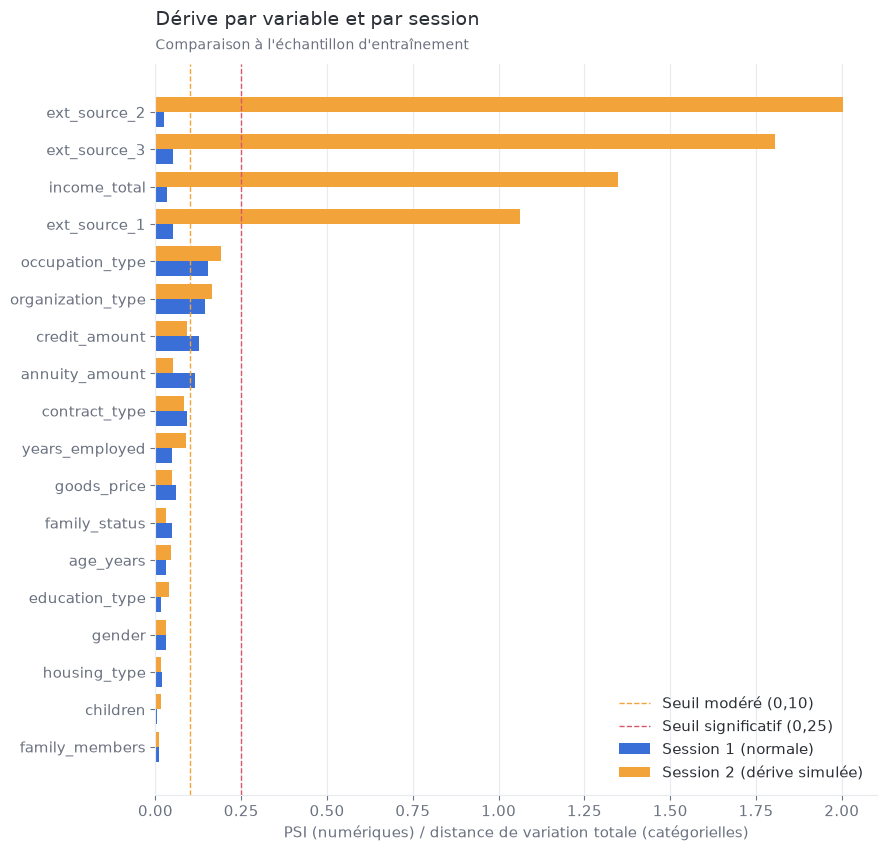

In [6]:
fig = plot_psi_by_session(drift[["feature", "session", "psi"]])

### Zoom sur les variables qui dérivent

On compare les distributions de la référence et des deux sessions pour les variables numériques
dont le PSI est le plus élevé en session 2.

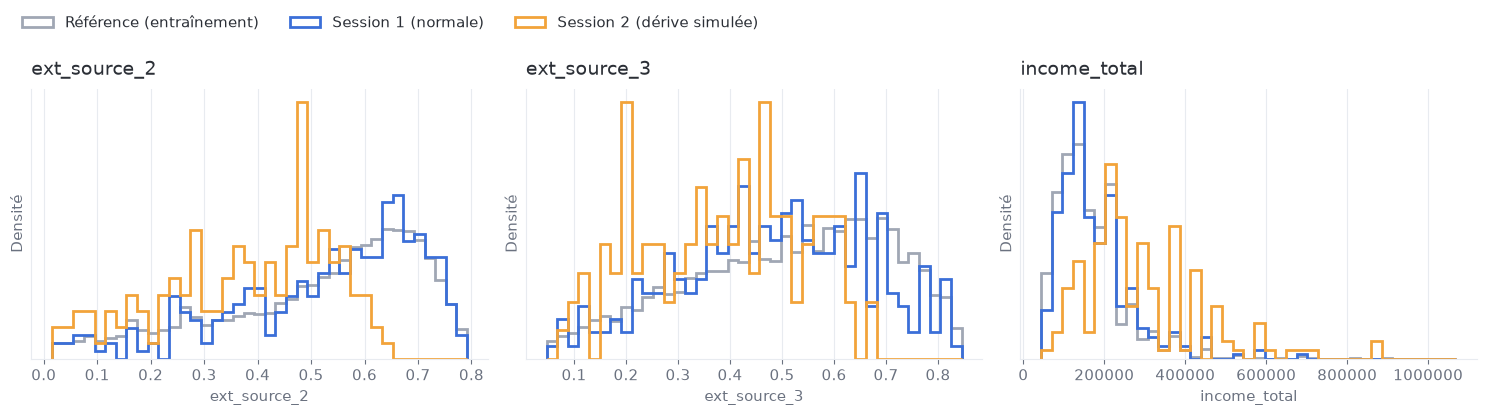

In [7]:
top_numeric = (
    drift.query("session == @SESSION_NAMES[1] and type == 'numeric'")
    .nlargest(3, "psi")["feature"].tolist()
)
groups = {"Référence (entraînement)": reference} | {n: d for n, d in prod.groupby("session")}
fig = plot_distributions(groups, top_numeric)

In [8]:
# Test de Kolmogorov-Smirnov sur ces variables (p-value < 0,05 : distributions différentes)
drift.query("feature in @top_numeric").pivot(index="feature", columns="session", values="ks_pvalue")

session,Session 1 (normale),Session 2 (dérive simulée)
feature,,
ext_source_2,0.5625,0.0
ext_source_3,0.0105,0.0
income_total,0.1575,0.0


## 3. Dérive de la sortie du modèle

Une dérive des entrées n'est grave que si elle change les décisions. On compare donc les scores
prédits en production à ceux que le modèle donne sur la référence, ainsi que le taux de refus
(score ≥ seuil métier issu de la fonction de coût 10×FN + FP).

In [9]:
pipeline = joblib.load(ROOT / "models/pipeline.joblib")
threshold = metadata["threshold"]
reference_scores = pd.Series(pipeline.predict_proba(prepare_features(reference))[:, 1])

scores = {"Référence (entraînement)": reference_scores} | {
    n: d["score"] for n, d in prod.groupby("session")
}
pd.DataFrame(
    {
        name: {
            "score moyen": s.mean(),
            "taux de refus": (s >= threshold).mean(),
            "PSI du score vs référence": psi(reference_scores, s) if name in SESSION_NAMES else None,
            "niveau": psi_level(psi(reference_scores, s)) if name in SESSION_NAMES else "—",
        }
        for name, s in scores.items()
    }
).T

,score moyen,taux de refus,PSI du score vs référence,niveau
Référence (entraînement),0.0816,0.2801,None,—
Session 1 (normale),0.0869,0.3067,0.0282,stable
Session 2 (dérive simulée),0.1535,0.5667,0.5726,drift significatif


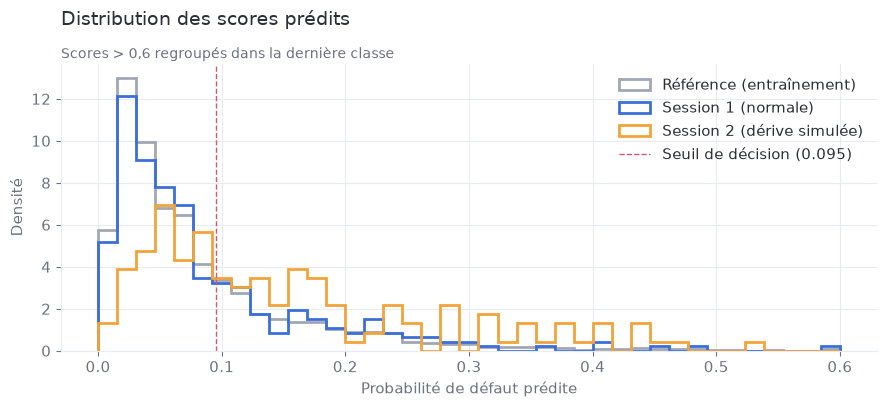

In [10]:
fig = plot_scores(scores, threshold)

## 4. Performance opérationnelle de l'API

La latence enregistrée est le temps de traitement de `/predict` côté serveur (validation,
inférence, journalisation). Ces logs datent d'avant l'optimisation de l'inférence
(voir `docs/optimisation_report.md`).

In [11]:
prod.groupby("session")["latency_ms"].describe(percentiles=[0.5, 0.95, 0.99])

,count,mean,std,min,50%,95%,99%,max
session,,,,,,,,
Session 1 (normale),300.0,10.2319,6.1794,8.963,9.500,10.8982,21.1899,107.278
Session 2 (dérive simulée),150.0,9.9328,3.3189,8.832,9.263,10.6494,26.5461,38.052


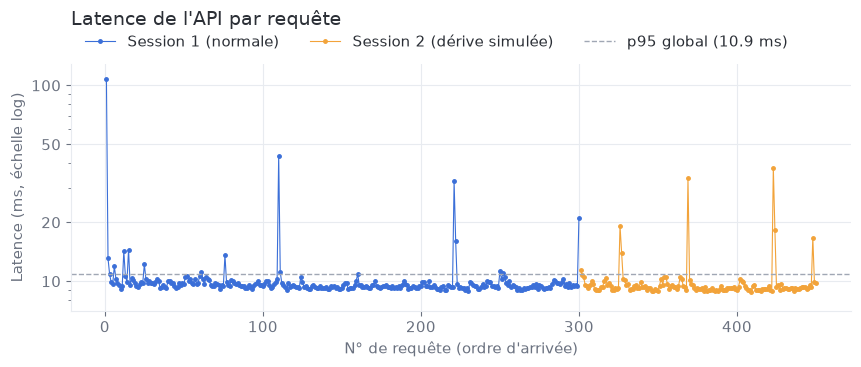

In [12]:
fig = plot_latency(prod[["logged_at", "latency_ms", "session"]])

## 5. Conclusions

**Session 1 : trafic normal, pas de dérive.**
- 14 variables sur 18 sont stables. Quatre dépassent le seuil modéré (0,10) sans atteindre
  0,25 : `occupation_type` (0,15), `organization_type` (0,14), `credit_amount` (0,13) et
  `annuity_amount` (0,12). Deux causes l'expliquent : le trafic rejoue `application_test.csv`,
  une population légèrement différente du jeu d'entraînement, et 300 requêtes suffisent à
  faire bruiter le PSI (avec 10 classes, le PSI attendu par simple hasard est déjà de quelques
  centièmes ; les variables catégorielles à plus de 50 modalités sont les plus touchées).
- La sortie du modèle est stable : PSI du score de 0,03, score moyen de 0,087 contre 0,082 sur
  la référence, taux de refus de 30,7 % contre 28,0 %.
- **Décision : aucune action, on continue la surveillance.**

**Session 2 : dérive simulée, détectée nettement.**
- Les quatre variables modifiées par la simulation ressortent en dérive significative, avec
  des PSI très au-dessus du seuil de 0,25 : `ext_source_2` (2,00), `ext_source_3` (1,81),
  `income_total` (1,35) et `ext_source_1` (1,06). Le test de KS le confirme (p-value ≈ 0).
  Les autres variables restent au niveau de la session 1 : `occupation_type` et
  `organization_type` sont toujours en dérive modérée (0,19 et 0,16), tout le reste est stable.
  La détection est donc **spécifique** : elle désigne les bonnes variables, sans fausse
  alerte sur les autres.
- L'impact métier est fort. La baisse des scores externes, qui comptent parmi les variables les plus
  prédictives sur Home Credit, fait monter le score moyen de 0,082 à 0,154 et le **taux de refus
  de 28 % à 57 %**. Le PSI du score vaut 0,57, soit une dérive significative. La hausse des
  revenus ne compense pas cet effet.
- **Décision dans un cas réel :** (1) chercher l'origine de la dérive (changement de
  fournisseur des scores externes, bug d'intégration, nouveau segment de clientèle) ; (2) si
  la population a vraiment changé, ré-entraîner le modèle sur des données récentes et
  recalculer le seuil de coût 10×FN + FP, car le seuil actuel (0,095) refuserait plus d'un
  client sur deux.

**Latence.** Aucune dégradation entre les sessions : p50 de 9,5 ms puis 9,3 ms, p95 de
10,9 ms puis 10,6 ms. Les quelques pics (jusqu'à 107 ms) sont ponctuels, et le premier
correspond au démarrage à froid de la première requête. Ces mesures datent d'avant
l'optimisation de l'inférence, qui ramène l'inférence p50 à 0,08 ms (voir
`docs/optimisation_report.md`).

**Mise en production de cette surveillance.** Calculer ces indicateurs sur des fenêtres
glissantes d'au moins 1 000 requêtes, pour limiter le bruit du PSI, avec ces alertes :
PSI > 0,25 sur une variable importante ou sur le score, ou écart de taux de refus supérieur
à 10 points par rapport à la référence. Le dashboard `dashboard/monitoring_app.py` et
`scripts/run_drift_analysis.py` utilisent les mêmes fonctions que ce notebook.
